In [552]:
import pandas as pd
import numpy as np
import math
from PIL import Image
from matplotlib import pyplot as plt

In [553]:
#img = np.asarray(Image.open("chelovechki/1.png").convert("L")) / float(255.0)
#print(img)

In [554]:
df = pd.DataFrame({
    'y' : [0] * 0,
    'et': [0] * 0,
    'er': [0] * 0
})

print(df)



Empty DataFrame
Columns: [y, et, er]
Index: []


In [555]:
def sigma(x):
  res = 0
  if x > 700:
    res = 1
  elif x < -700:
    res = 0
  else: 
    res = 1 / (1 + math.exp(-x))
  return res
def porog(x):
  res = 0
  if x >= 0:
    res = 1
  return res

neironcount = 0

class akson:
  def __init__(self):
    self.wes = 0
  def __repr__(self):
    return str(self.wes)

class neiron:
  def __init__(self):
      global neironcount
      self.aksons = []
      self.neirons = []
      self.id = neironcount
      neironcount += 1
      self.lastvalue = 0
  def getvalue(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

class inputneiron(neiron):
  def setvalue(self, x):
    self.myvalue = x
  def getvalue(self):
    #print(f"в нейроне {self.id} значение {self.myvalue} x")
    self.lastvalue = self.myvalue
    return self.myvalue
  def __init__(self):
    super().__init__()
    self.myvalue = 0

class outputneiron(neiron):
  def getvalue(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

In [556]:
import random

layer1 = [inputneiron() for i in range(36)]
layer2 = [neiron() for i in range(6)]
layer3 = outputneiron()
biasneiron = inputneiron()
biasneiron.setvalue(1)
neironsall = layer1 + layer2 + [layer3]
aksonsall = []

layer1.append(biasneiron)
layer2.append(biasneiron)
layer3.neirons.append(biasneiron)

for n in layer2:
  n.neirons = layer1
  for j in range(len(layer1)):
    n.aksons.append(akson())

layer3.neirons = layer2
for j in range(len(layer2)):
  layer3.aksons.append(akson())

for n in neironsall:
  for a in n.aksons:
    a.wes = random.uniform(-1, 1)
    aksonsall.append(a)

for a in aksonsall:
  a.wes = random.uniform(-1, 1)

In [557]:
def showwesa():
  for a in aksonsall:
    print(a.wes)
#print(aksonsall)
#showwesa()
print(aksonsall)

[0.8005994680859645, -0.7408105132349005, 0.05420206234575642, -0.16721083832312011, -0.9218101528711804, 0.16255146429868428, -0.03262711929241657, -0.7903862849757419, -0.73838283918921, -0.4096624471551855, -0.2577235598168284, -0.25421370517815656, -0.2961862927671879, 0.7636087099201281, -0.7397472945601926, 0.6363634001316347, -0.7440262708472143, -0.7132917919229098, 0.16207524295802567, -0.49490041321717704, -0.6344922002558493, 0.024482707807263804, 0.8808093031032067, 0.40527182125000416, 0.9158642308686289, 0.6521752236501828, 0.7442036861937158, 0.3733283668140035, 0.0991145420282149, 0.0549647883789528, 0.47929483127971606, 0.40871822231410415, -0.7309486841086938, 0.36019597021565475, -0.5405336339419622, 0.5670655021774902, 0.19193236199650943, -0.5269803499437613, 0.6389390167263258, -0.728773672947473, -0.09618665344874877, 0.3089259826781543, 0.26634670726381127, 0.9871752845182573, -0.874840963304004, -0.4919852270608791, 0.19702783507294042, 0.41511364417241725, -0.

Теперь надо разобраться с загрузкой датасета и использованием изображений из папки chelovechki

In [558]:
import requests
import os
'''
## Set the GitHub repository and folder details
repo_url = "https://api.github.com/repos/ashotnafig1/Neironki/contents/Lab02/chelovechki"
local_path = "chelovechki"

os.makedirs(local_path, exist_ok=True)
## Send a GET request to the GitHub API
response = requests.get(repo_url)

## Iterate through the folder contents and download each file
for item in response.json():
    if item["type"] == "file":
        file_url = item["download_url"]
        file_name = item["name"]
        file_path = f"{local_path}/{file_name}"

        ## Download the file
        file_response = requests.get(file_url)
        with open(file_path, "wb") as file:
            file.write(file_response.content)
'''

'\n## Set the GitHub repository and folder details\nrepo_url = "https://api.github.com/repos/ashotnafig1/Neironki/contents/Lab02/chelovechki"\nlocal_path = "chelovechki"\n\nos.makedirs(local_path, exist_ok=True)\n## Send a GET request to the GitHub API\nresponse = requests.get(repo_url)\n\n## Iterate through the folder contents and download each file\nfor item in response.json():\n    if item["type"] == "file":\n        file_url = item["download_url"]\n        file_name = item["name"]\n        file_path = f"{local_path}/{file_name}"\n\n        ## Download the file\n        file_response = requests.get(file_url)\n        with open(file_path, "wb") as file:\n            file.write(file_response.content)\n'

In [559]:
# возвращает np массив изображения, причём нормализованный
def readimage(path):
    return np.asarray(Image.open(path).convert("L")) / float(255.0) 

tablefull = pd.read_csv("chelovechki/tablica.txt", sep=' ')
tablefull["y"] = None
tablefull["err"] = None

print(tablefull)

table = tablefull.sample(frac = 0.9, random_state = 228)
tabletest = tablefull.drop(table.index)

def getimage(number):
    return readimage("chelovechki/" + str(number) + ".png").flatten()
for i in range(len(table)):
    print(getimage(i))

    id  class     y   err
0    0      1  None  None
1    1      1  None  None
2    2      1  None  None
3    3      1  None  None
4    4      0  None  None
5    5      1  None  None
6    6      0  None  None
7    7      1  None  None
8    8      0  None  None
9    9      0  None  None
10  10      1  None  None
11  11      0  None  None
12  12      0  None  None
13  13      1  None  None
14  14      0  None  None
15  15      0  None  None
16  16      0  None  None
17  17      1  None  None
18  18      0  None  None
19  19      0  None  None
20  20      0  None  None
21  21      1  None  None
22  22      1  None  None
23  23      1  None  None
24  24      1  None  None
25  25      0  None  None
26  26      0  None  None
27  27      1  None  None
28  28      0  None  None
29  29      1  None  None
30  30      1  None  None
31  31      0  None  None
[0. 0. 0. 1. 0. 0. 0. 1. 0. 1. 1. 0. 0. 0. 1. 1. 0. 1. 0. 0. 0. 1. 0. 0.
 0. 0. 1. 0. 1. 0. 0. 1. 0. 0. 0. 1.]
[0. 0. 1. 0. 0. 0. 1. 0. 1. 1. 

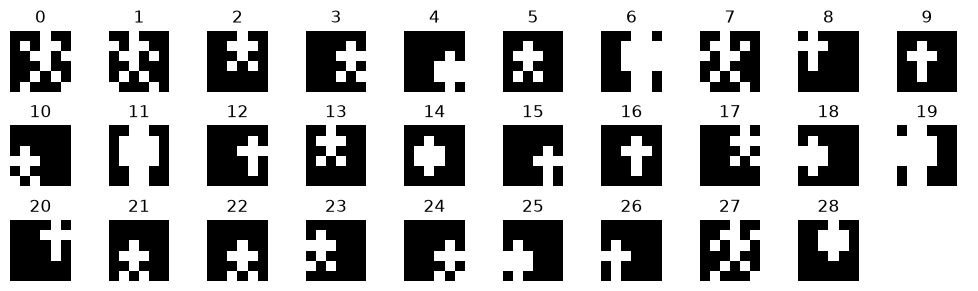

In [560]:
imagescount = len(table)
cols = 10
rows = math.ceil(imagescount / cols)
fig, axes = plt.subplots(rows, cols, figsize=(cols, rows))
axes = axes.flatten() 
for i in range(min(imagescount, 40)):
    img = Image.open("chelovechki/" + str(i) + ".png").convert("L")
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"{i}")
    axes[i].axis('off')
for j in range(imagescount, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()


In [561]:
#
def Test(X):
  for i in range(len(X)):
    layer1[i].setvalue(X[i])
  return layer3.getvalue()


In [562]:
def bigtest():
  s = 0
  sq = 0
  for i, clas in table.iterrows():
    X = getimage(i)
    y_pred = Test(X)
    table.loc[i, "y"]  = y_pred
    table.loc[i, "err"] = table.loc[i, "class"] - y_pred
    s += table.loc[i, "err"]
    sq += (table.loc[i, "err"])**2
  return float(s), float(sq)

summa, summaq = bigtest()
print(summa, summaq)
print(table)

-8.0 12.0
    id  class  y err
4    4      0  1  -1
6    6      0  0   0
22  22      1  1   0
13  13      1  0   1
8    8      0  1  -1
14  14      0  1  -1
2    2      1  1   0
11  11      0  0   0
0    0      1  1   0
30  30      1  1   0
9    9      0  1  -1
27  27      1  1   0
7    7      1  0   1
15  15      0  1  -1
31  31      0  0   0
17  17      1  1   0
1    1      1  1   0
29  29      1  1   0
10  10      1  1   0
21  21      1  1   0
18  18      0  1  -1
28  28      0  0   0
20  20      0  1  -1
3    3      1  1   0
26  26      0  1  -1
23  23      1  1   0
24  24      1  1   0
12  12      0  1  -1
25  25      0  1  -1


In [563]:
param = 0.35


#showwesa()

In [564]:
def getBIGerror():
    s = 0
    sq = 0
    for i, clas in table.iterrows():
        X = getimage(i)
        y_pred = Test(X)
        table.loc[i, "y"]  = y_pred
        table.loc[i, "err"] = table.loc[i, "class"] - y_pred
        s += table.loc[i, "err"]
        sq += (table.loc[i, "err"])**2
    return float(s), float(sq)
    

In [565]:
# опять поставлю на выходной нейрон сигмоиду чтобы красиво работало
def getvaluePOROG(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

def getvalueSIGMO(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

outputneiron.getvalue = getvalueSIGMO


In [566]:
# эта чухня формирует нормальные обучающие массивы
X = np.stack([getimage(i) for i in tablefull["id"].values])
y = tablefull["class"].values.astype(np.int32)
y = np.where(y == 0, -1, 1)
N = len(X)
idx = np.random.permutation(N)
ntr = int(N * 0.8)
tr = idx[:ntr]
ts = idx[ntr:]
Xtr = X[tr]
Xts = X[ts]
ytr = y[tr]
yts = y[ts]

всё что выше была заготовка самих данных, алгоритма обучения и способов как это связать.
Пора проверять чё я там настрочил

In [567]:
maloe = 10e-4
speed = 0.1

epohi = 0
bigerrors = []

In [568]:
def kernelrbf(X1, X2, gamma=1.0):
    d2 = (X1**2).sum(1)[:, None] + (X2**2).sum(1)[None, :] - 2 * X1 @ X2.T
    return np.exp(-gamma * d2) + 1.0

class SVM:
    def __init__(self, C=1.0, gamma=1.0, epochs=500, kernelfunc=kernelrbf):
        self.C, self.gamma, self.epochs = C, gamma, epochs
        self.kernelfunc = kernelfunc

    # самое интересное
    def fit(self, x, d):
        # задаётся матрица ядерной функции, это матрица "меры сходства"
        # для всех обучающих данных, сама функция ядра подставляется
        K = self.kernelfunc(x, x, self.gamma)
        # коэффициенты альфа, отражают важность вектора для классификации
        a = np.zeros(len(d))
        for жжж in range(self.epochs):
            # просто проход по всей обучающей выборке. d это сигнал класса
            # причём -1 это стоит, 1 это идёт. Перевод 0 -> -1 сделан при формировании выборок
            for i in range(len(d)):
                # g это тупо производная от той двойной суммы по текущему a
                g = 1 - d[i] * ((a * d) @ K[:, i])
                # a2 это новая альфа, и с ней приколы есть
                # выражение g / K это сдвиг к вершине параболы и там дальше толстые книжки ужас
                a2 = a[i] + g / K[i, i]
                # и потом a2 должно быть от 0 до C для сохранения так называемой выпуклости задачи
                if a2 > self.C:
                    a[i] = self.C
                elif a2 < 0:
                    a[i] = 0
                else:
                    a[i] = a2
        sv = a > 1e-8
        self.a, self.d, self.x = a[sv], d[sv], x[sv]
        return self

    def f(self, x):
        return (self.a * self.d) @ self.kernelfunc(self.x, x, self.gamma)

    def predict(self, x):
        return np.sign(self.f(x))

gamma = 1 / (Xtr.shape[1] * Xtr.var())
svm1 = SVM(C=10, gamma=gamma).fit(Xtr, ytr)


In [569]:
#plt.plot(np.arange(0, epohi + 1), bigerrors)

In [570]:
#print(table)
#showwesa()
print(aksonsall)
with open("wesaBACKPRO.txt", "w") as file:
    for a in aksonsall:
        file.write(str(a) + '\n')


[0.8005994680859645, -0.7408105132349005, 0.05420206234575642, -0.16721083832312011, -0.9218101528711804, 0.16255146429868428, -0.03262711929241657, -0.7903862849757419, -0.73838283918921, -0.4096624471551855, -0.2577235598168284, -0.25421370517815656, -0.2961862927671879, 0.7636087099201281, -0.7397472945601926, 0.6363634001316347, -0.7440262708472143, -0.7132917919229098, 0.16207524295802567, -0.49490041321717704, -0.6344922002558493, 0.024482707807263804, 0.8808093031032067, 0.40527182125000416, 0.9158642308686289, 0.6521752236501828, 0.7442036861937158, 0.3733283668140035, 0.0991145420282149, 0.0549647883789528, 0.47929483127971606, 0.40871822231410415, -0.7309486841086938, 0.36019597021565475, -0.5405336339419622, 0.5670655021774902, 0.19193236199650943, -0.5269803499437613, 0.6389390167263258, -0.728773672947473, -0.09618665344874877, 0.3089259826781543, 0.26634670726381127, 0.9871752845182573, -0.874840963304004, -0.4919852270608791, 0.19702783507294042, 0.41511364417241725, -0.

In [571]:
outputneiron.getvalue = getvaluePOROG
getBIGerror()
#print(table)
#showwesa()


def testsvm(svm):
    return (svm.predict(Xts) == yts).mean()
print(testsvm(svm1))

0.2857142857142857


In [572]:
def kernellinear(X1, X2, b = 1):
    return X1 @ X2.T + b
svm2 = SVM(C = 10, kernelfunc = kernellinear).fit(Xtr, ytr)
print(testsvm(svm2))

0.2857142857142857


In [573]:
def kernelpoly(X1, X2, b = 1):
    return (X1 @ X2.T + b)**2
svm3 = SVM(C = 10, kernelfunc = kernelpoly).fit(Xtr, ytr)
print(testsvm(svm3))

0.2857142857142857


In [574]:
pred = svm1.predict(Xts)
print("acc =", (pred == yts).mean())
print("ошибки на изгоях с индексами", ts[pred != yts])

acc = 0.2857142857142857
ошибки на изгоях с индексами [22 28 10 12 29]


In [575]:

with open("wesaBACKPRO.txt", "r") as file:
    line = file.readline()
    i = 0
    while line:
        aksonsall[i].wes = float(line)
        i += 1
        line = file.readline()

In [576]:
# ИНТЕРФЭЭЭЙС
%gui qt6

import sys
from PyQt6 import QtWidgets as qw

allbuttons = []
class krutayaknopka(qw.QPushButton):
    def __init__(self, text, myvalue, parent = ...):
        super().__init__()
        self.myvalue = myvalue
        self.activated = 1
        self.selectcolor()
        self.clicked.connect(self.selectcolor)
    def selectcolor(self):
        if self.activated == 0:
            self.activated = 1
            self.setStyleSheet("background-color: #FFFFFF")
        else:
            self.activated = 0
            self.setStyleSheet("background-color: #000000")
        self.delegat()
    def delegat(self):
        return

class krutoeokno(qw.QMainWindow):
    def __init__(self):
        super().__init__()
        razmer = 6

        layout = qw.QHBoxLayout()
        self.label = qw.QLabel("sadsadsad")
        layout.addWidget(self.label)
        grid = qw.QGridLayout()
        gridwidget = qw.QWidget()
        gridwidget.setFixedSize(50 * razmer, 50 * razmer)
        gridwidget.setLayout(grid)
        layout.addWidget(gridwidget)

        for row in range(razmer):
            for col in range(razmer):
                b = krutayaknopka("", row * razmer + col)
                b.setFixedSize(50, 50)
                allbuttons.append(b)
                grid.addWidget(b, row, col)
                
        
        self.setWindowTitle("акошко")
        self.setGeometry(100, 50, 800, 500)
        container = qw.QWidget()
        container.setLayout(layout)
        self.setCentralWidget(container)
        
window = krutoeokno()

def predictevent(kacherishka):
    X = np.array([float(b.activated) for b in allbuttons]).reshape(1, -1)
    y = svm1.predict(X)[0]
    if y == 1:
        window.label.setText("идёт")
    else:
        window.label.setText("стоит")
krutayaknopka.delegat = predictevent

window.show()